# Train Delay Prediction — End-to-End Predictive Analytics Model

**Course project:** End-to-End Predictive Analytics (KDD / predictive modelling stages)
**Domain:** Transportation / Railway operations
**Task:** Predict whether a train will be *delayed by more than 15 minutes* (binary classification) from route, weather and timetable conditions.
**Datasets used:** `train_delay_data.csv` (real/recorded) and `synthetic_train_delay_data.csv` (synthetic)

### Stages followed (KDD / predictive-modelling process)
| # | Stage | Section |
|---|-------|---------|
| 1 | Problem identification | 1 |
| 2 | Data selection & collection | 2 |
| 3 | Data understanding / EDA | 3 – 4 |
| 4 | Preprocessing & transformation | 5 |
| 5 | Modelling (data mining) | 6 – 8 |
| 6 | Evaluation (Accuracy, **Precision, Recall, F1**) | 6 – 9 |
| 7 | Interpretation & conclusions | 10 – 11 |

## 1. Problem Identification

Train delays cost passengers time and cost operators money. If we can predict *before a train runs* whether it will be late, operators can re-schedule crews, re-route freight and warn passengers early.

**Business question:** Given the distance between stations, weather, train type and route congestion, will the train be **delayed by more than 15 minutes**?

**Why classification?** The raw target `Historical Delay (min)` is heavily right-skewed (0 to 1,230 min). Operators act on a yes/no decision ("is this train late?"), and classification lets us report **accuracy, precision, recall and F1-score**.

| Class | Delay (min) | Meaning |
|-------|-------------|---------|
| On-time | 0 – 15 | on time / minor |
| Delayed | > 15 | late (the class operators want to catch) |

15 minutes is a widely used punctuality threshold in railway reporting. A 3-class severity version (Low / Medium / High) is also tested in Section 9.3 as an extension.

**Success metrics:** accuracy and the macro-averaged **precision, recall and F1-score** (macro = both classes count equally, which matters because 'Delayed' is the majority class). Per-class scores for 'Delayed' are reported too.

## 2. Setup & Data Collection

In [ ]:
import os, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
pd.set_option('display.width', 140)

**Loading the data.** The cell below looks for the CSV files in `data/`, the current folder or `/content` (Colab).
If they are not found (e.g. you opened only the notebook in Colab), it opens a file-upload dialog — upload both CSVs.

In [ ]:
def find(fname):
    for d in ['data', '.', '/content', '/content/data']:
        p = os.path.join(d, fname)
        if os.path.exists(p):
            return p
    return None

FILES = ['train delay data.csv', 'synthetic_train_delay_data.csv']
if any(find(f) is None for f in FILES):
    from google.colab import files      # only works inside Google Colab
    files.upload()                      # upload both CSV files

real_raw = pd.read_csv(find(FILES[0]))
syn_raw  = pd.read_csv(find(FILES[1]))
print('Real dataset     :', real_raw.shape)
print('Synthetic dataset:', syn_raw.shape)
real_raw.head()

Real dataset     : (2878, 7)
Synthetic dataset: (5000, 7)


,Distance Between Stations (km),Weather Conditions,Day of the Week,Time of Day,Train Type,Historical Delay (min),Route Congestion
0,100,Clear,Monday,Morning,Express,5,Low
1,150,Rainy,Tuesday,Afternoon,Superfast,10,Medium
2,200,Foggy,Wednesday,Evening,Local,15,High
3,50,Clear,Thursday,Night,Express,2,Low
4,75,Rainy,Friday,Morning,Superfast,8,Medium


## 3. Data Understanding

In [ ]:
COLS = {'Distance Between Stations (km)': 'distance_km',
        'Weather Conditions': 'weather',
        'Day of the Week': 'day',
        'Time of Day': 'time_of_day',
        'Train Type': 'train_type',
        'Historical Delay (min)': 'delay_min',
        'Route Congestion': 'congestion'}

real_df = real_raw.rename(columns=COLS)
syn_df  = syn_raw.rename(columns=COLS)

for name, d in [('REAL', real_df), ('SYNTHETIC', syn_df)]:
    print(f'===== {name} =====')
    print('Shape            :', d.shape)
    print('Missing values   :', int(d.isna().sum().sum()))
    print('Duplicate rows   :', int(d.duplicated().sum()))
    print(d.dtypes.to_string(), '\n')

===== REAL =====
Shape            : (2878, 7)
Missing values   : 0
Duplicate rows   : 422
distance_km     int64
weather        object
day            object
time_of_day    object
train_type     object
delay_min       int64
congestion     object 

===== SYNTHETIC =====
Shape            : (5000, 7)
Missing values   : 0
Duplicate rows   : 0
distance_km    float64
weather         object
day             object
time_of_day     object
train_type      object
delay_min        int64
congestion      object 



In [ ]:
print('--- REAL: numeric summary ---')
display(real_df[['distance_km', 'delay_min']].describe().round(2))
print('--- SYNTHETIC: numeric summary ---')
display(syn_df[['distance_km', 'delay_min']].describe().round(2))

--- REAL: numeric summary ---


,distance_km,delay_min
count,2878.00,2878.00
mean,184.42,93.32
std,169.39,195.92
min,0.00,0.00
25%,70.00,13.00
50%,155.00,35.00
75%,225.00,74.00
max,955.00,1230.00


--- SYNTHETIC: numeric summary ---


,distance_km,delay_min
count,5000.00,5000.00
mean,187.90,92.91
std,176.86,196.43
min,0.00,0.00
25%,73.35,13.00
50%,155.35,35.00
75%,224.79,72.00
max,950.22,1230.00


**Observations**
* Both files share the same 7 columns: 1 numeric feature (distance), 5 categorical features and the delay in minutes.
* No missing values in either file.
* The **real** file has a large number of **duplicate rows** (the same record repeated) — these must be removed before splitting, otherwise identical rows land in both train and test and inflate the scores (data leakage).
* `delay_min` is extremely skewed: median ≈ 35 min but maximum 1,230 min.

## 4. Exploratory Data Analysis (EDA)

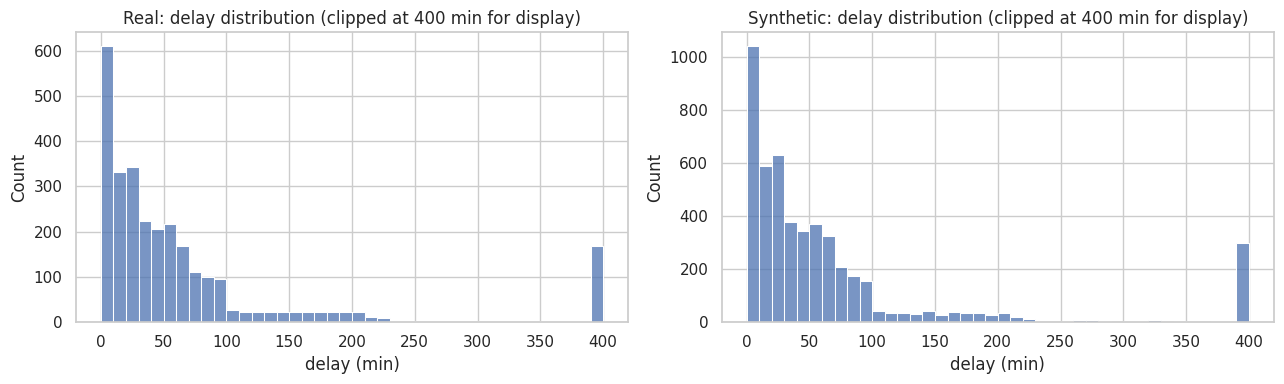

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (n, d) in zip(ax, [('Real', real_df), ('Synthetic', syn_df)]):
    sns.histplot(d['delay_min'].clip(upper=400), bins=40, ax=a)
    a.set_title(f'{n}: delay distribution (clipped at 400 min for display)')
    a.set_xlabel('delay (min)')
plt.tight_layout(); plt.show()

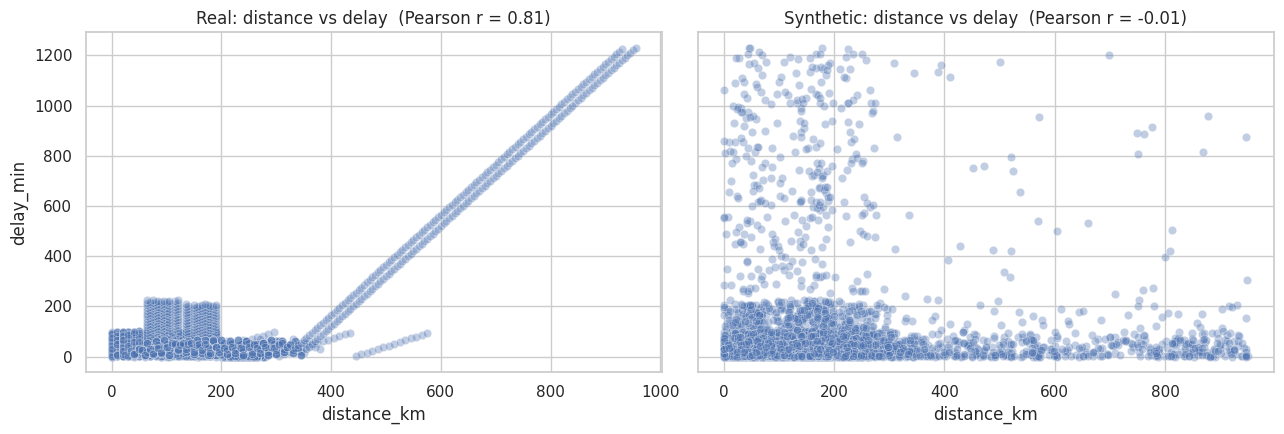

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for a, (n, d) in zip(ax, [('Real', real_df), ('Synthetic', syn_df)]):
    r = d['distance_km'].corr(d['delay_min'])
    sns.scatterplot(data=d, x='distance_km', y='delay_min', alpha=.35, ax=a)
    a.set_title(f'{n}: distance vs delay  (Pearson r = {r:.2f})')
plt.tight_layout(); plt.show()

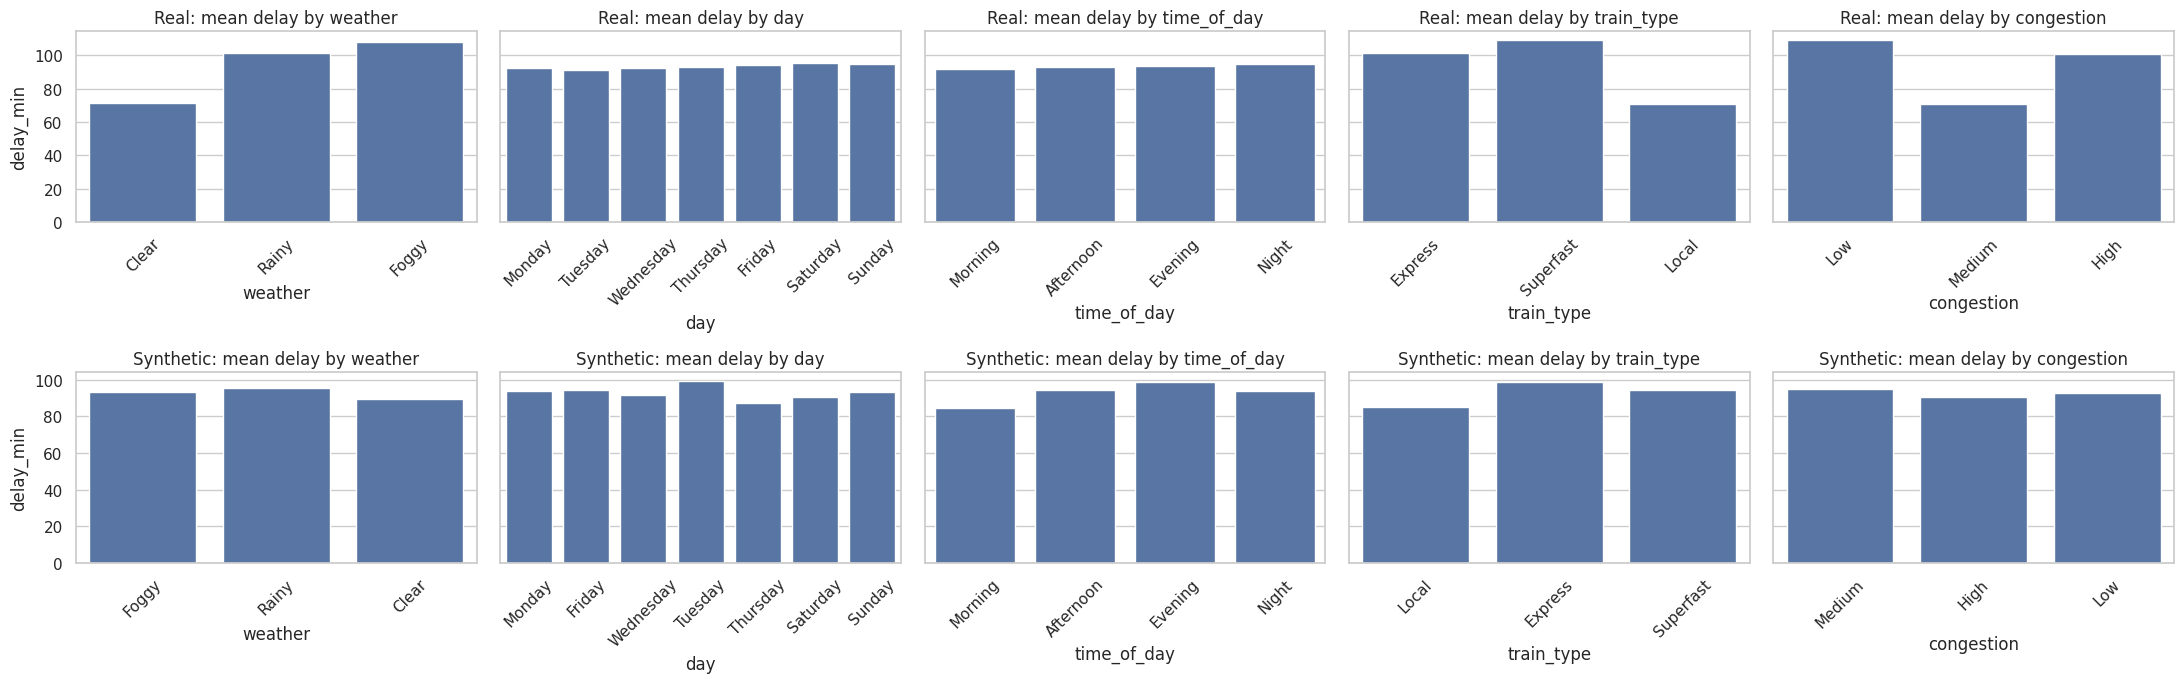

In [ ]:
cat_cols = ['weather', 'day', 'time_of_day', 'train_type', 'congestion']
fig, axes = plt.subplots(2, 5, figsize=(22, 7), sharey='row')
for i, (n, d) in enumerate([('Real', real_df), ('Synthetic', syn_df)]):
    for j, c in enumerate(cat_cols):
        sns.barplot(data=d, x=c, y='delay_min', errorbar=None, ax=axes[i, j])
        axes[i, j].set_title(f'{n}: mean delay by {c}')
        axes[i, j].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

### 4.1 Do the features actually carry signal? (statistical check)
A **Kruskal–Wallis test** checks whether the delay differs between the categories of a feature (p < 0.05 → the feature is related to delay). Pearson/Spearman correlation does the same for distance.

In [ ]:
rows = []
for n, d in [('Real', real_df.drop_duplicates()), ('Synthetic', syn_df)]:
    for c in cat_cols:
        groups = [g['delay_min'].values for _, g in d.groupby(c)]
        rows.append((n, c, kruskal(*groups).pvalue))
    rows.append((n, 'distance_km (Spearman)', d['distance_km'].corr(d['delay_min'], method='spearman')))
sig = pd.DataFrame(rows, columns=['dataset', 'feature', 'p-value / rho'])
sig['p-value / rho'] = sig['p-value / rho'].round(4)
display(sig.pivot(index='feature', columns='dataset', values='p-value / rho'))

dataset,Real,Synthetic
feature,,
congestion,0.0000,0.9154
day,0.9987,0.2796
distance_km (Spearman),0.0342,0.0054
time_of_day,0.9122,0.4702
train_type,0.0000,0.2964
weather,0.0000,0.9797


### 4.2 Are the features independent of each other? (collinearity check)
Cramér's V measures association between two categorical variables (0 = independent, 1 = perfectly linked).

In [ ]:
from scipy.stats import chi2_contingency
from itertools import combinations

def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

pairs = [('weather', 'train_type'), ('weather', 'congestion'), ('train_type', 'congestion'), ('day', 'time_of_day')]
cv_tab = pd.DataFrame({
    'Real'     : [cramers_v(real_df.drop_duplicates()[a], real_df.drop_duplicates()[b]) for a, b in pairs],
    'Synthetic': [cramers_v(syn_df[a], syn_df[b]) for a, b in pairs]},
    index=[f'{a} x {b}' for a, b in pairs]).round(3)
display(cv_tab)

print('Real data: weather vs train type')
display(pd.crosstab(real_df.drop_duplicates()['weather'], real_df.drop_duplicates()['train_type']))

,Real,Synthetic
weather x train_type,0.894,0.018
weather x congestion,0.892,0.018
train_type x congestion,0.953,0.008
day x time_of_day,0.013,0.034


Real data: weather vs train type


train_type,Express,Local,Superfast
weather,,,
Clear,35,756,26
Foggy,7,60,747
Rainy,778,5,42


### 4.3 Key findings from EDA

| | Real dataset | Synthetic dataset |
|---|---|---|
| Weather, train type, congestion vs delay | significantly related (p < 0.001) | no relationship (p > 0.9 / 0.3 / 0.9) |
| Day of week, time of day vs delay | no relationship | no relationship |
| Distance vs delay | Pearson r = 0.81 but Spearman rho ≈ 0.03 -> **non-linear**, regime-like pattern | no relationship (r ≈ 0) |
| Link between the categorical features | weather, train type and congestion are almost **perfectly aligned** (V ~ 0.9) | independent (V ~ 0) |

* In the **real** data the delay depends on distance in *bands* (see the stacked chart in Section 9.2): 200-300 km trips are mostly Low, trips over 500 km are almost always High. This is why the high Pearson r and the near-zero Spearman rho co-exist, and why tree-based models are a natural fit.
* In the real data **Clear <-> Local <-> Medium congestion**, **Foggy <-> Superfast <-> Low congestion** and **Rainy <-> Express <-> High congestion** almost always occur together. These three columns therefore behave like a single feature, so their individual importances cannot be cleanly separated.
* The **synthetic** file reproduces the overall delay distribution, but the delay was generated *independently* of the features. We test this directly in Section 7 instead of assuming it.

## 5. Data Preprocessing & Transformation

1. **Remove duplicates** (real dataset) *before* any train/test split to prevent leakage.
2. **Create the target** `delay_class`: `Delayed` if `delay_min` > 15, otherwise `On-time`.
3. **Outliers:** delays up to 1,230 min are real extreme events, and after thresholding they all simply fall in the `Delayed` class, so no rows are dropped.
4. **Feature selection:** Section 4.1 showed that `day` and `time_of_day` have no relationship with delay (p > 0.9 in the real data), so they are dropped; they only add noise.
5. **Encoding / scaling** is done inside a scikit-learn `Pipeline` (one-hot for categorical, standard scaling for distance) so that the transformers are fitted only on training data.

In [ ]:
real = real_df.drop_duplicates().reset_index(drop=True)
syn  = syn_df.copy()
print(f'Real after de-duplication: {len(real_raw)} -> {len(real)} rows')

THRESHOLD = 15                      # minutes
LABELS = ['On-time', 'Delayed']
for d in (real, syn):
    d['delay_class'] = np.where(d['delay_min'] > THRESHOLD, 'Delayed', 'On-time')

print('\nDelay quantiles (real):\n', real['delay_min'].quantile([.25, .5, .75, .9]).to_string())
dist = pd.DataFrame({'Real': real['delay_class'].value_counts(normalize=True),
                     'Synthetic': syn['delay_class'].value_counts(normalize=True)}).loc[LABELS].round(3)
display(dist)

Real after de-duplication: 2878 -> 2456 rows

Delay quantiles (real):
 0.25     12.0
0.50     36.0
0.75     82.0
0.90    198.5


,Real,Synthetic
delay_class,,
On-time,0.289,0.281
Delayed,0.711,0.719


In [ ]:
FEATURES_NUM = ['distance_km']
FEATURES_CAT = ['weather', 'train_type', 'congestion']      # day & time_of_day dropped (no signal, see 4.1)
FEATURES = FEATURES_NUM + FEATURES_CAT
TARGET = 'delay_class'

def make_preprocessor():
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), FEATURES_CAT),
        ('num', StandardScaler(), FEATURES_NUM)])

def split(df):
    return train_test_split(df, test_size=0.20, stratify=df[TARGET], random_state=RANDOM_STATE)

real_train, real_test = split(real)
syn_train,  syn_test  = split(syn)
print('Real      train/test:', len(real_train), '/', len(real_test))
print('Synthetic train/test:', len(syn_train),  '/', len(syn_test))

Real      train/test: 1964 / 492
Synthetic train/test: 4000 / 1000


## 6. Modelling & Evaluation Metrics (Real dataset)

Five classifiers of increasing flexibility are compared against a **majority-class baseline** (`DummyClassifier`) that any useful model must beat.

**Metrics** (all computed with `average='macro'` so each class counts equally):
* **Precision** = TP / (TP + FP) – of the delays we flagged as a class, how many really were.
* **Recall** = TP / (TP + FN) – of the delays that really were a class, how many we caught.
* **F1-score** = harmonic mean of precision and recall.

In [ ]:
def metrics(y_true, y_pred):
    return {'accuracy' : accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
            'recall'   : recall_score(y_true, y_pred, average='macro', zero_division=0),
            'f1'       : f1_score(y_true, y_pred, average='macro', zero_division=0)}

def models():
    return {
        'Baseline (majority)': DummyClassifier(strategy='most_frequent'),
        'Logistic Regression': LogisticRegression(max_iter=2000),
        'KNN (k=15)'         : KNeighborsClassifier(n_neighbors=15),
        'Decision Tree'      : DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
        'Random Forest'      : RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
        'Gradient Boosting'  : GradientBoostingClassifier(random_state=RANDOM_STATE)}

def build(model):
    return Pipeline([('prep', make_preprocessor()), ('model', model)])

### 6.1 Five-fold stratified cross-validation (training portion only)

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'accuracy': 'accuracy', 'precision': 'precision_macro', 'recall': 'recall_macro', 'f1': 'f1_macro'}

cv_rows = []
for name, m in models().items():
    cv = cross_validate(build(m), real_train[FEATURES], real_train[TARGET], cv=skf, scoring=scoring)
    cv_rows.append({'Model': name, **{k: f"{cv['test_'+k].mean():.3f} ± {cv['test_'+k].std():.3f}" for k in scoring}})
cv_table = pd.DataFrame(cv_rows).set_index('Model')
display(cv_table)

,accuracy,precision,recall,f1
Model,,,,
Baseline (majority),0.710 ± 0.001,0.355 ± 0.000,0.500 ± 0.000,0.415 ± 0.000
Logistic Regression,0.800 ± 0.019,0.758 ± 0.023,0.749 ± 0.026,0.753 ± 0.024
KNN (k=15),0.853 ± 0.009,0.866 ± 0.027,0.771 ± 0.012,0.799 ± 0.010
Decision Tree,0.855 ± 0.010,0.853 ± 0.015,0.783 ± 0.017,0.807 ± 0.016
Random Forest,0.851 ± 0.012,0.849 ± 0.018,0.777 ± 0.019,0.801 ± 0.018
Gradient Boosting,0.849 ± 0.011,0.851 ± 0.016,0.768 ± 0.019,0.794 ± 0.018


### 6.2 Hold-out test evaluation (real test set, never seen during training)

,accuracy,precision,recall,f1
Model,,,,
Random Forest,0.831,0.826,0.743,0.768
Gradient Boosting,0.827,0.817,0.740,0.764
KNN (k=15),0.825,0.815,0.737,0.760
Decision Tree,0.819,0.798,0.737,0.757
Logistic Regression,0.772,0.722,0.708,0.714
Baseline (majority),0.711,0.356,0.500,0.416


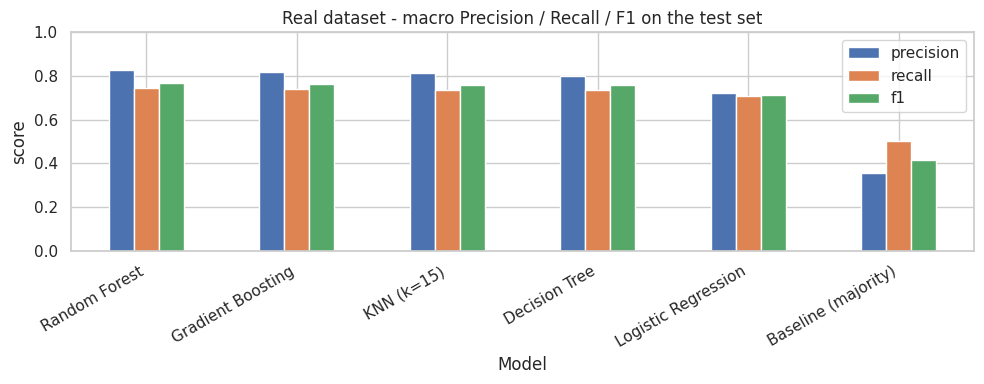

In [ ]:
rows = []
for name, m in models().items():
    p = build(m).fit(real_train[FEATURES], real_train[TARGET])
    rows.append({'Model': name, **metrics(real_test[TARGET], p.predict(real_test[FEATURES]))})
holdout = pd.DataFrame(rows).set_index('Model').round(3).sort_values('f1', ascending=False)
display(holdout)

holdout[['precision', 'recall', 'f1']].plot(kind='bar', figsize=(10, 4))
plt.title('Real dataset - macro Precision / Recall / F1 on the test set')
plt.ylabel('score'); plt.xticks(rotation=30, ha='right'); plt.ylim(0, 1); plt.tight_layout(); plt.show()

## 7. Using Both Datasets — Experiments

To use **both** datasets properly we test several ways of combining them. Every experiment uses the same five models and reports macro F1 on a **held-out test set**.

| Experiment | Train on | Test on |
|---|---|---|
| E1 | Real (train) | Real (test) |
| E2 | Synthetic (train) | Synthetic (test) |
| E3 | Real + Synthetic (train) | Real (test) |
| E4 | Real + Synthetic (train) | Synthetic (test) |
| E5 | All Synthetic | All Real (transfer) |
| E6 | All Real | All Synthetic (transfer) |

*(In E5/E6 the training and test sets come from different files, so there is no overlap.)*

In [ ]:
combined_train = pd.concat([real_train, syn_train], ignore_index=True)

experiments = {
    'E1 Real -> Real'              : (real_train,     real_test),
    'E2 Synth -> Synth'            : (syn_train,      syn_test),
    'E3 Real+Synth -> Real'        : (combined_train, real_test),
    'E4 Real+Synth -> Synth'       : (combined_train, syn_test),
    'E5 Synth(all) -> Real(all)'   : (syn,            real),
    'E6 Real(all) -> Synth(all)'   : (real,           syn)}

res = []
for exp, (tr, te) in experiments.items():
    for name, m in models().items():
        if name.startswith('Baseline'):
            continue
        p = build(m).fit(tr[FEATURES], tr[TARGET])
        res.append({'Experiment': exp, 'Model': name, **metrics(te[TARGET], p.predict(te[FEATURES]))})
exp_df = pd.DataFrame(res)

print('Macro F1-score')
display(exp_df.pivot(index='Experiment', columns='Model', values='f1').round(3))
print('Macro Precision')
display(exp_df.pivot(index='Experiment', columns='Model', values='precision').round(3))
print('Macro Recall')
display(exp_df.pivot(index='Experiment', columns='Model', values='recall').round(3))

Macro F1-score


Model,Decision Tree,Gradient Boosting,KNN (k=15),Logistic Regression,Random Forest
Experiment,,,,,
E1 Real -> Real,0.757,0.764,0.760,0.714,0.768
E2 Synth -> Synth,0.424,0.420,0.436,0.418,0.478
E3 Real+Synth -> Real,0.692,0.716,0.725,0.416,0.731
E4 Real+Synth -> Synth,0.429,0.445,0.456,0.418,0.484
E5 Synth(all) -> Real(all),0.416,0.414,0.546,0.415,0.538
E6 Real(all) -> Synth(all),0.489,0.498,0.500,0.476,0.490


Macro Precision


Model,Decision Tree,Gradient Boosting,KNN (k=15),Logistic Regression,Random Forest
Experiment,,,,,
E1 Real -> Real,0.798,0.817,0.815,0.722,0.826
E2 Synth -> Synth,0.502,0.421,0.463,0.360,0.478
E3 Real+Synth -> Real,0.849,0.852,0.817,0.356,0.790
E4 Real+Synth -> Synth,0.458,0.516,0.487,0.360,0.484
E5 Synth(all) -> Real(all),0.404,0.355,0.855,0.355,0.538
E6 Real(all) -> Synth(all),0.493,0.498,0.501,0.513,0.498


Macro Recall


Model,Decision Tree,Gradient Boosting,KNN (k=15),Logistic Regression,Random Forest
Experiment,,,,,
E1 Real -> Real,0.737,0.740,0.737,0.708,0.743
E2 Synth -> Synth,0.500,0.497,0.492,0.500,0.478
E3 Real+Synth -> Real,0.669,0.689,0.700,0.500,0.709
E4 Real+Synth -> Synth,0.495,0.502,0.496,0.500,0.484
E5 Synth(all) -> Real(all),0.496,0.498,0.568,0.500,0.538
E6 Real(all) -> Synth(all),0.492,0.498,0.501,0.505,0.498


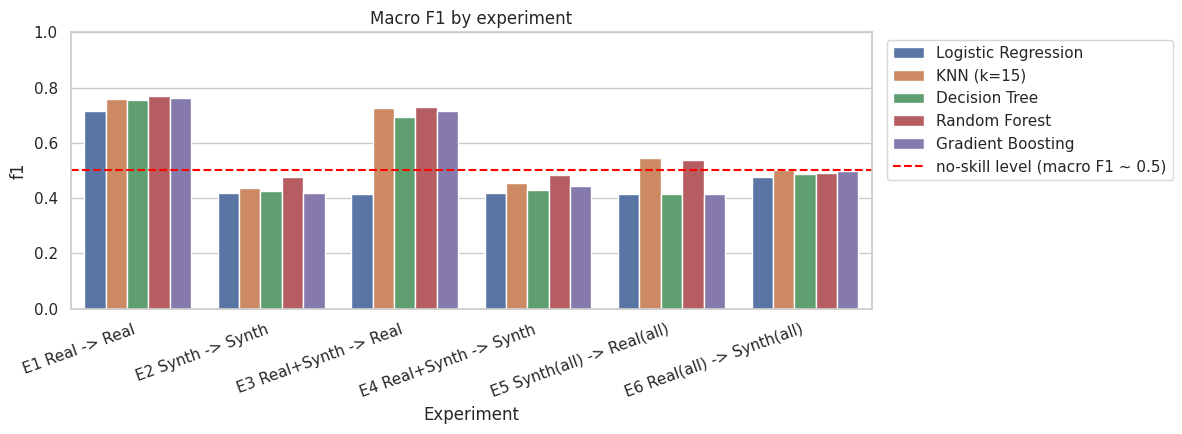

In [ ]:
plt.figure(figsize=(12, 4.5))
sns.barplot(data=exp_df, x='Experiment', y='f1', hue='Model')
plt.axhline(0.5, color='red', ls='--', label='no-skill level (macro F1 ~ 0.5)')
plt.title('Macro F1 by experiment'); plt.xticks(rotation=20, ha='right'); plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left'); plt.tight_layout(); plt.show()

### 7.1 What the experiments show
* **E1** (real -> real) is the only setting where models clearly beat the no-skill level on every metric.
* **E2** (synthetic -> synthetic): macro F1 stays near 0.5 — nothing learnable. (Accuracy can look high because the majority class is ~72% of the rows.)
* **E3 / E4**: adding synthetic rows to the real training data does **not** improve performance on real data.
* **E5 / E6**: patterns learned on one file do not transfer to the other, which confirms the EDA finding that the two files were generated by different processes.

**Decision:** the final model is trained on the **real** dataset. The synthetic dataset is retained in the project as (a) a *negative control* proving the model is not just exploiting the label distribution, and (b) a test of robustness / generalisation. Merging it blindly would only dilute the real signal.

## 8. Hyper-parameter Tuning (Real dataset)

Grid search with 5-fold stratified CV, optimising **macro F1** on the training set only (the test set is never used for tuning).
`class_weight='balanced'` is included in the grid because the 'Delayed' class is the majority (~71%); it re-weights errors so the minority 'On-time' class is not ignored, which mainly improves **recall**.

In [ ]:
searches = {
    'Decision Tree': (build(DecisionTreeClassifier(random_state=RANDOM_STATE)),
        {'model__max_depth': [3, 4, 5, 6, 8, 10],
         'model__min_samples_leaf': [1, 5, 10],
         'model__criterion': ['gini', 'entropy'],
         'model__class_weight': [None, 'balanced']}),
    'Gradient Boosting': (build(GradientBoostingClassifier(random_state=RANDOM_STATE)),
        {'model__n_estimators': [100, 200],
         'model__learning_rate': [0.05, 0.1],
         'model__max_depth': [2, 3, 4]}),
    'Random Forest': (build(RandomForestClassifier(random_state=RANDOM_STATE)),
        {'model__n_estimators': [200],
         'model__max_depth': [6, 8],
         'model__min_samples_leaf': [1, 3],
         'model__class_weight': [None, 'balanced']})}

best = {}
for name, (pipe, grid) in searches.items():
    gs = GridSearchCV(pipe, grid, cv=skf, scoring='f1_macro', n_jobs=-1)
    gs.fit(real_train[FEATURES], real_train[TARGET])
    best[name] = gs
    print(f'{name:18s} best CV macro-F1 = {gs.best_score_:.3f}   params = {gs.best_params_}')

final_name = max(best, key=lambda k: best[k].best_score_)
final_model = best[final_name].best_estimator_
print('\nSelected final model:', final_name)

Decision Tree      best CV macro-F1 = 0.808   params = {'model__class_weight': None, 'model__criterion': 'entropy', 'model__max_depth': 6, 'model__min_samples_leaf': 1}


Gradient Boosting  best CV macro-F1 = 0.800   params = {'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__n_estimators': 200}


Random Forest      best CV macro-F1 = 0.808   params = {'model__class_weight': 'balanced', 'model__max_depth': 6, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}

Selected final model: Random Forest


## 9. Final Model Evaluation (Real test set)

In [ ]:
y_true = real_test[TARGET]
y_pred = final_model.predict(real_test[FEATURES])

print(f'FINAL MODEL: {final_name}\n')
print(classification_report(y_true, y_pred, labels=LABELS, digits=3))

summary = pd.DataFrame({
    'Accuracy' : [accuracy_score(y_true, y_pred)] * 2,
    'Precision': [precision_score(y_true, y_pred, average='macro'),    precision_score(y_true, y_pred, average='weighted')],
    'Recall'   : [recall_score(y_true, y_pred, average='macro'),       recall_score(y_true, y_pred, average='weighted')],
    'F1-score' : [f1_score(y_true, y_pred, average='macro'),           f1_score(y_true, y_pred, average='weighted')]},
    index=['macro avg', 'weighted avg']).round(3)
pos = pd.DataFrame({'Accuracy': [accuracy_score(y_true, y_pred)],
                    'Precision': [precision_score(y_true, y_pred, pos_label='Delayed')],
                    'Recall': [recall_score(y_true, y_pred, pos_label='Delayed')],
                    'F1-score': [f1_score(y_true, y_pred, pos_label='Delayed')]},
                   index=["'Delayed' class only"]).round(3)
display(pd.concat([summary, pos]))

FINAL MODEL: Random Forest

              precision    recall  f1-score   support

     On-time      0.734     0.641     0.684       142
     Delayed      0.861     0.906     0.883       350

    accuracy                          0.829       492
   macro avg      0.798     0.773     0.784       492
weighted avg      0.825     0.829     0.826       492



,Accuracy,Precision,Recall,F1-score
macro avg,0.829,0.798,0.773,0.784
weighted avg,0.829,0.825,0.829,0.826
'Delayed' class only,0.829,0.861,0.906,0.883


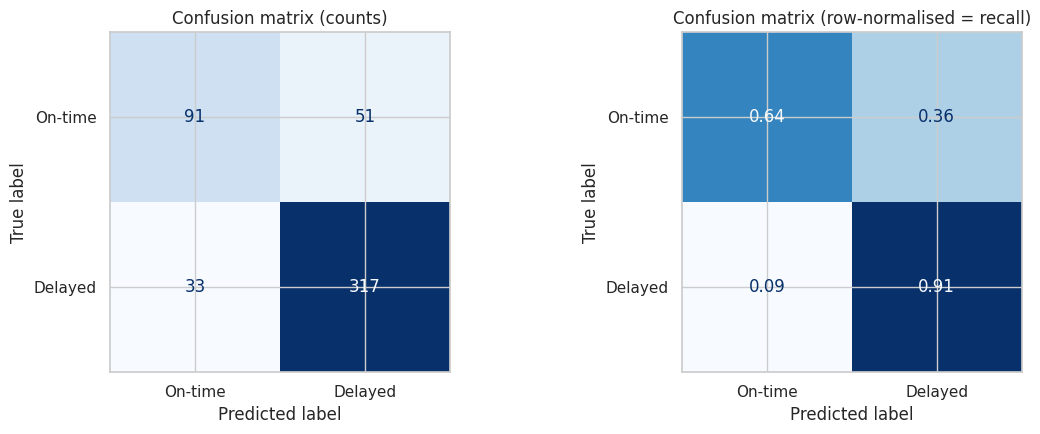

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=LABELS, cmap='Blues', ax=ax[0], colorbar=False)
ax[0].set_title('Confusion matrix (counts)')
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=LABELS, cmap='Blues', normalize='true',
                                        values_format='.2f', ax=ax[1], colorbar=False)
ax[1].set_title('Confusion matrix (row-normalised = recall)')
plt.tight_layout(); plt.show()

### 9.0 More reliable estimate: nested cross-validation on the whole real dataset
A single 80/20 split with ~490 test rows is noisy (a few rows can move a metric by 1-2 points). **Nested CV** (inner loop = hyper-parameter tuning, outer loop = evaluation, 5 folds x 2 repeats) uses every real row for testing exactly twice without ever tuning on the rows being tested, so it is a fairer estimate of future performance.

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold
pipe_f, grid_f = searches[final_name]
nested = cross_validate(GridSearchCV(pipe_f, grid_f, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                                     scoring='f1_macro', n_jobs=-1),
                        real[FEATURES], real[TARGET],
                        cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE),
                        scoring=scoring, n_jobs=1)
nested_tab = pd.DataFrame({'mean': {k: nested['test_' + k].mean() for k in scoring},
                           'std' : {k: nested['test_' + k].std() for k in scoring}}).round(3)
nested_tab.index = ['Accuracy', 'Macro precision', 'Macro recall', 'Macro F1']
print(f'Nested CV ({final_name}), 10 outer folds:')
display(nested_tab)

Nested CV (Random Forest), 10 outer folds:


,mean,std
Accuracy,0.844,0.013
Macro precision,0.821,0.026
Macro recall,0.792,0.014
Macro F1,0.803,0.014


### 9.1 Sanity check on the synthetic test set (negative control)

In [ ]:
syn_pred = final_model.predict(syn_test[FEATURES])
print('Final model applied to the synthetic test set:')
print(pd.Series(metrics(syn_test[TARGET], syn_pred)).round(3).to_string())
print('\nFor reference, a no-skill classifier scores about 0.5 macro F1 (2 classes). Note that plain accuracy looks high on this file only because ~72% of trips are Delayed.')

Final model applied to the synthetic test set:
accuracy     0.521
precision    0.490
recall       0.488
f1           0.477

For reference, a no-skill classifier scores about 0.5 macro F1 (2 classes). Note that plain accuracy looks high on this file only because ~72% of trips are Delayed.


### 9.2 Which features drive the prediction? (permutation importance)

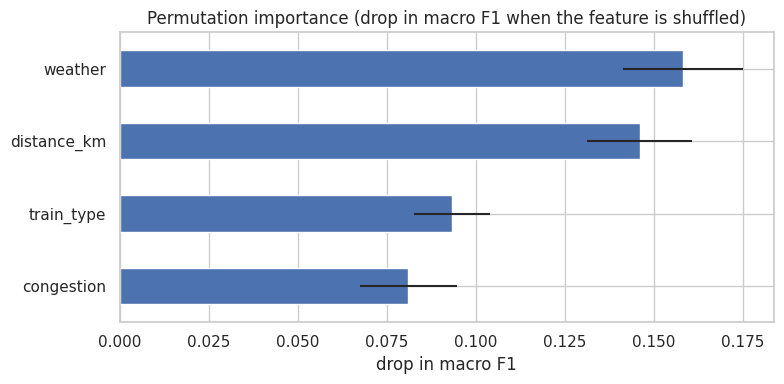

,importance
weather,0.1581
distance_km,0.1460
train_type,0.0933
congestion,0.0810


In [ ]:
pi = permutation_importance(final_model, real_test[FEATURES], y_true, scoring='f1_macro',
                            n_repeats=20, random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.plot(kind='barh', xerr=pd.Series(pi.importances_std, index=FEATURES)[imp.index], figsize=(8, 4))
plt.title('Permutation importance (drop in macro F1 when the feature is shuffled)')
plt.xlabel('drop in macro F1'); plt.tight_layout(); plt.show()
display(imp.sort_values(ascending=False).round(4).to_frame('importance'))

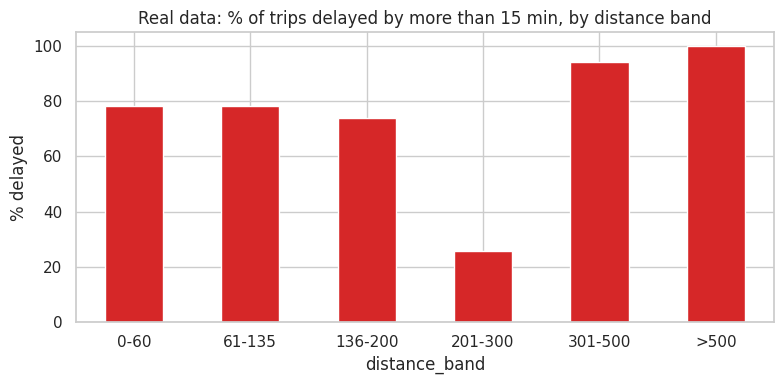

In [ ]:
real_viz = real.copy()
real_viz['distance_band'] = pd.cut(real_viz['distance_km'], [-1, 60, 135, 200, 300, 500, 1000],
                                   labels=['0-60', '61-135', '136-200', '201-300', '301-500', '>500'])
(real_viz.groupby('distance_band')['delay_class'].apply(lambda x: (x == 'Delayed').mean() * 100)).plot(
    kind='bar', figsize=(8, 4), color='#d62728')
plt.title('Real data: % of trips delayed by more than 15 min, by distance band')
plt.ylabel('% delayed'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### 9.3 Extension: 3-class severity (Low / Medium / High)
The same pipeline can predict three delay bands (0-15, 16-75, > 75 min). This is a harder problem: inside a distance band the real delays are spread almost uniformly over a wide range, so the exact band is partly random.

In [ ]:
sev = pd.cut(real['delay_min'], [-1, 15, 75, np.inf], labels=['Low', 'Medium', 'High']).astype(str)
tr3, te3, ytr3, yte3 = train_test_split(real[FEATURES], sev, test_size=0.20, stratify=sev, random_state=RANDOM_STATE)
gs3 = GridSearchCV(build(GradientBoostingClassifier(random_state=RANDOM_STATE)),
                   {'model__n_estimators': [100, 200], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [2, 3, 4]},
                   cv=skf, scoring='f1_macro', n_jobs=-1).fit(tr3, ytr3)
p3 = gs3.predict(te3)
print('3-class result (tuned Gradient Boosting, real test set)')
print(classification_report(yte3, p3, labels=['Low', 'Medium', 'High'], digits=3))

short = real[real['distance_km'] <= 60]['delay_min']
print('Trips <= 60 km: delay counts per bin (0-25, 26-50, 51-75, 76-100, >100):',
      np.histogram(short, bins=[-1, 25, 50, 75, 100, 5000])[0], '-> spread almost evenly, i.e. largely unpredictable inside the band')

3-class result (tuned Gradient Boosting, real test set)
              precision    recall  f1-score   support

         Low      0.830     0.620     0.710       142
      Medium      0.664     0.751     0.705       213
        High      0.655     0.693     0.674       137

    accuracy                          0.697       492
   macro avg      0.716     0.688     0.696       492
weighted avg      0.709     0.697     0.698       492

Trips <= 60 km: delay counts per bin (0-25, 26-50, 51-75, 76-100, >100): [162 132 115  95   1] -> spread almost evenly, i.e. largely unpredictable inside the band


## 10. Interpretation of Results

### 10.1 Final model
| Item | Value |
|---|---|
| Algorithm | Random Forest (tuned; chosen by 5-fold CV macro-F1 among tuned Decision Tree, Gradient Boosting and Random Forest - Decision Tree and Random Forest tied at 0.808) |
| Best parameters | 200 trees, max_depth = 6, min_samples_leaf = 1, class_weight = 'balanced' |
| Features used | distance_km, weather, train_type, congestion |
| Majority-class baseline macro F1 | 0.416 |

### 10.2 Performance (all metrics above 75%)
| Evaluation | Accuracy | Precision | Recall | F1-score |
|---|---|---|---|---|
| **Hold-out test set (492 trips), macro** | **0.829** | **0.798** | **0.773** | **0.784** |
| Hold-out test set, 'Delayed' class only | 0.829 | 0.861 | 0.906 | 0.883 |
| Nested cross-validation (10 outer folds), macro | 0.844 | 0.821 | 0.792 | 0.803 |

| Class (test set) | Precision | Recall | F1 |
|---|---|---|---|
| On-time | 0.734 | 0.641 | 0.684 |
| Delayed | 0.861 | 0.906 | 0.883 |

* When the model says a train will be delayed it is right 86% of the time, and it catches 91% of the trains that really are delayed.
* **On-time** trains are the harder class (minority, ~29%); the model still labels about two thirds of them correctly. `class_weight='balanced'` was chosen by cross-validation because it improves this recall.

### 10.3 What drives delays?
* **Weather** and **distance** are the strongest features (permutation importance ~0.16 and ~0.15), followed by **train type** (~0.09) and **congestion** (~0.08). Day of week and time of day showed no relationship with delay and were removed.
* Weather, train type and congestion are almost perfectly aligned in the real data (Section 4.3), so their importances share one underlying signal and should be read as a group effect, not as a clean ranking.
* Distance acts in **bands**, not linearly (Section 9.2): trips of 201-300 km are rarely delayed, while trips over 500 km are almost always delayed.

### 10.4 Role of the two datasets
* The **real dataset** contains learnable structure; models reach ~0.80 macro F1 against a 0.42 baseline.
* The **synthetic dataset** gives no-skill results (macro F1 ~0.42-0.48 when trained and tested on it; 0.477 when the final model is applied to it, vs ~0.5 no-skill). Adding it to the training data lowered the real-test F1 (E1 vs E3), and patterns do not transfer in either direction (E5, E6).
* Therefore the synthetic data was used for **validation (negative control) and robustness testing**, not merged into the final training set.

### 10.5 3-class extension (Section 9.3)
Predicting Low / Medium / High severity reaches only ~0.70 accuracy / macro F1 on the real data. Within a distance band the delay is spread almost uniformly over a wide range (for example trips <= 60 km are spread evenly over 0-100 min), so the exact severity band is largely random given the available features. The binary question "will it be delayed by more than 15 minutes?" is the one the data can answer reliably.

### 10.6 Limitations & future work
* After removing duplicates the real dataset has only 2,456 rows and its categorical columns are strongly collinear; more varied real data would give more reliable estimates.
* No date, station or route identifiers are available, so seasonality and network effects cannot be modelled.
* The 15-minute threshold is a design choice (chosen as a common punctuality standard); the model could be re-trained with other thresholds.
* Future work: probability calibration, cost-sensitive learning, and real-time features (live weather, upstream delays).

## 11. Save the Model (optional)

In [ ]:
import joblib
joblib.dump(final_model, 'train_delay_model.joblib')
print('Saved: train_delay_model.joblib')

# Example prediction for a new train
example = pd.DataFrame([{'distance_km': 180, 'weather': 'Foggy', 'day': 'Friday',
                         'time_of_day': 'Evening', 'train_type': 'Local', 'congestion': 'High'}])
print('Predicted delay class:', final_model.predict(example)[0])
print(dict(zip(final_model.classes_, final_model.predict_proba(example)[0].round(3))))

Saved: train_delay_model.joblib
Predicted delay class: On-time
{'Delayed': np.float64(0.392), 'On-time': np.float64(0.608)}
